<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

<ul style="list-style:none;padding-left:0;margin:0">
  <li><a href="01_Einleitung.ipynb">1. Einleitung</a></li>
  <li><a href="02_Datensammlung.ipynb">2. Datensammlung</a></li>
  <li><strong>3. Preprocessing</strong></li>
  <li><a href="04_Explorative_Datenanalyse.ipynb">4. Explorative Datenanalyse</a></li>
  <li><a href="05_Modellierung.ipynb">5. Modellierung</a></li>
  <li><a href="06_Backtest.ipynb">6. Backtest &amp; Performance</a></li>
  <li><a href="07_Fazit.ipynb">7. Fazit</a></li>
</ul>

<h1 id="3">3. Preprocessing</h1>

Bevor die Daten quantitativ analysiert werden, muss zuerst die Qualität des Datensatzes sichergestellt werden. Dies wird in diesem Projekt als *Preprocessing* genannt.

Das Preprocessing wird in den folgenden Schritten durchgeführt:

- [Standardisierung & Coverage](#31)
- [Fehlende Daten (NaN)](#32)
- [Duplikate & Preis-Ausreisser](#33)
- [Fehlende Daten (Zeilen)](#34)
- [Validierung & Speicherung](#35)

Es sind zwei wichtige Bemerkungen zu machen:
- Es wird angenommen, dass yfinance korrekte Daten liefert.
- Da das Projekt bereits einen grossen Rahmen hat, werden für Features nur der `close` betrachtet. Das heisst `open`, `high`, `low` und `volume` werden ignoriert, also nicht bereinigt. Dementsprechend gibt es z. B. keine *Volume-Features*. Dennoch werden alle Daten weitergegeben für einfache Weiterentwicklung des Projektes.

In [1]:
# Zelle 1: Imports & Konfiguration
from pairs_trading import data_io as io
from pairs_trading import preprocessing as pp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "data/raw"
PATTERN = "sp500_1min_*.csv"

Als erstes werden die Rohdaten gesammelt, in einen Dataframe zusammengestellt und die Struktur ermittelt

In [2]:
# Zelle 2: Rohdaten laden
df = io.load_unprocessed_data(
    data_dir=DATA_DIR,
    pattern=PATTERN,
    parse_dates=["datetime"],
)
symbols_beginning = set(df["symbol"].unique())


[Unprocessed Data Load]
Verzeichnis: data/raw
Pattern: sp500_1min_*.csv
Gefundene Dateien: 172

[Unprocessed Data]
Shape: (33629536, 7)
Spalten: ['symbol', 'datetime', 'open', 'high', 'low', 'close', 'volume']

Head:
  symbol             datetime        open        high         low       close  \
0    MMM  2025-11-07 14:30:00  163.910004  163.929993  163.389999  163.820007   
1    MMM  2025-11-07 14:31:00  163.910004  163.979996  163.910004  163.979996   
2    MMM  2025-11-07 14:32:00  163.889999  163.910004  163.699997  163.699997   
3    MMM  2025-11-07 14:33:00  163.934998  164.179993  163.429993  163.429993   
4    MMM  2025-11-07 14:34:00  163.429993  163.990005  163.419998  163.839996   

    volume  
0  45015.0  
1   2321.0  
2   1533.0  
3   3947.0  
4   4934.0  


<h2 id="31">3.1. Standardisierung & Coverage</h2>

Bevor statistische Analysen oder Modellierungen durchgeführt werden, muss ein grundlegendes Verständnis des verwendeten Datensatzes geschaffen werden. In diesem Abschnitt werden Struktur, Umfang und Qualität der zugrunde liegenden Kursdaten untersucht.

Da die Datensammlung im Verlaufe des Projektes angepasst wurde, wurde es notwendig `datetime` zu standardisieren. Anschliessend wird der Dataframe nach `Symbol` und innerhalb von `Symbol` nach `datetime` sortiert.

In [3]:
# Zelle 3: Zeitstempel standardisieren (UTC) & sortieren
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")
df = df.sort_values(by=["symbol", "datetime"]).reset_index(drop=True)

Da in der folgenden Analyse ausschließlich Aktien betrachtet werden sollen, die über den gesamten Beobachtungszeitraum Bestandteil des S&P 500 waren, werden zunächst alle Symbole entfernt, die erst während des Zeitraums aufgenommen wurden oder vorzeitig aus dem Index ausgeschieden sind.

In [4]:
# Zelle 4: Datenbereinigung nach Coverage
df, removed_symbols = pp.filter_symbols_by_full_coverage(df)

print(f"Anzahl entfernte Ticker: {len(removed_symbols)}")
print(f"Anzahl verbleibende Ticker: {df['symbol'].nunique()}")
print(f'Entfernte Ticker: {removed_symbols}')

Anzahl entfernte Ticker: 42
Anzahl verbleibende Ticker: 481
Entfernte Ticker: Index(['ARES', 'BK', 'BNY', 'CAG', 'CASY', 'CIEN', 'COHR', 'CPB', 'CRH',
       'CTRA', 'CVNA', 'DAY', 'DD', 'ECHO', 'EPAM', 'FDXF', 'FI', 'FISV',
       'FIX', 'FLEX', 'HOLX', 'HONA', 'IPG', 'K', 'LITE', 'LKQ', 'LW', 'MHK',
       'MMC', 'MOH', 'MRSH', 'MRVL', 'MTCH', 'NVR', 'PAYC', 'POOL', 'SATS',
       'SNDK', 'SOLS', 'TT', 'VEEV', 'VRT'],
      dtype='str', name='symbol')


<h2 id="32">3.2. Fehlende Daten (NaN)</h2>

Es wird überprüft, in welchem Umfang `NaN`-Datenlücken existieren und wie sie sich über die Aktien und Zeit verteilen.

Diese Analysen ermöglichen es, die Datenqualität vor der Modellierung quantitativ zu bewerten und entscheiden zu können, ob bestimmte Symbole aufgrund von Datenlücken ausgeschlossen oder bearbeitet werden müssen.

Es gibt 481 Aktien mit mindestens einem fehlenden Wert.

Top 5 betroffene Ticker (fehlende Zeilen):
symbol
ERIE    37906
AIZ     32867
NDSN    30345
CINF    25796
GL      25145
dtype: int64


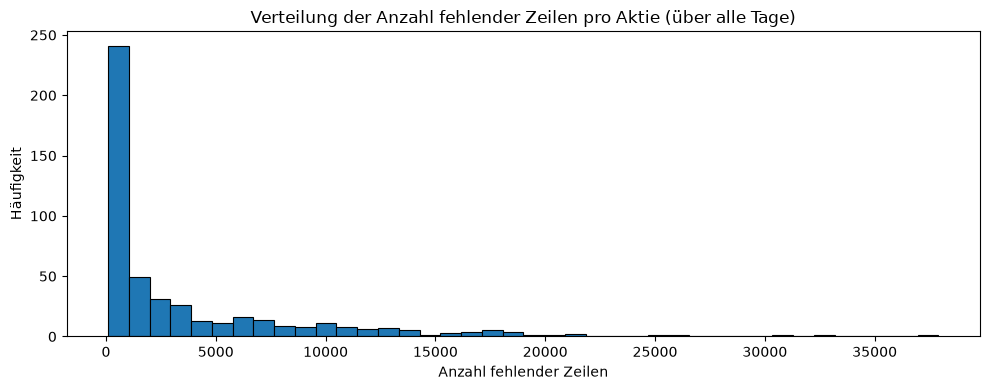

In [5]:
# Zelle 5: Aktien mit fehlenden Werten
missing = pp.analyze_missing_values(df, top_n=5, bins=40, show_plot=True)

Die meisten Aktien haben nur sehr wenige fehlende Datenpunkte, einige wenige jedoch deutlich mehr.

Nachdem festgestellt wurde, welche Aktien unvollständige Zeitreihen besitzen, wird nun untersucht, **wann** diese Datenlücken im jeweiligen Tagesverlauf auftreten. Diese Analyse hilft zu erkennen, ob die fehlenden Werte zufällig verteilt sind oder ob sie zu bestimmten Zeiten des Handelstages öfter vorkommen.

Ein grosses Auftreten zu bestimmten Uhrzeiten kann auf **technische Ursachen** (z. B. Marktpause) oder **marktbedingte Phasen geringer Aktivität** hindeuten.

Zur Analyse wird der Zeitstempel der Daten extrahiert und auf Minutenebene aggregiert. Anschließend wird gezählt, wie viele Werte zu jedem Zeitpunkt fehlen. Das Ergebnis wird in Form eines Liniendiagramms visualisiert, um die Häufigkeit fehlender Werte über den jeweiligen Tag hinweg zu untersuchen. Die Legende zum Diagramm wurde zur Übersichtlichkeit auskommentiert.

/Users/ryanmikus/Development/Python/00_Quant/HS25_ML/pairs_trading/preprocessing/data_quality.py:142: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))


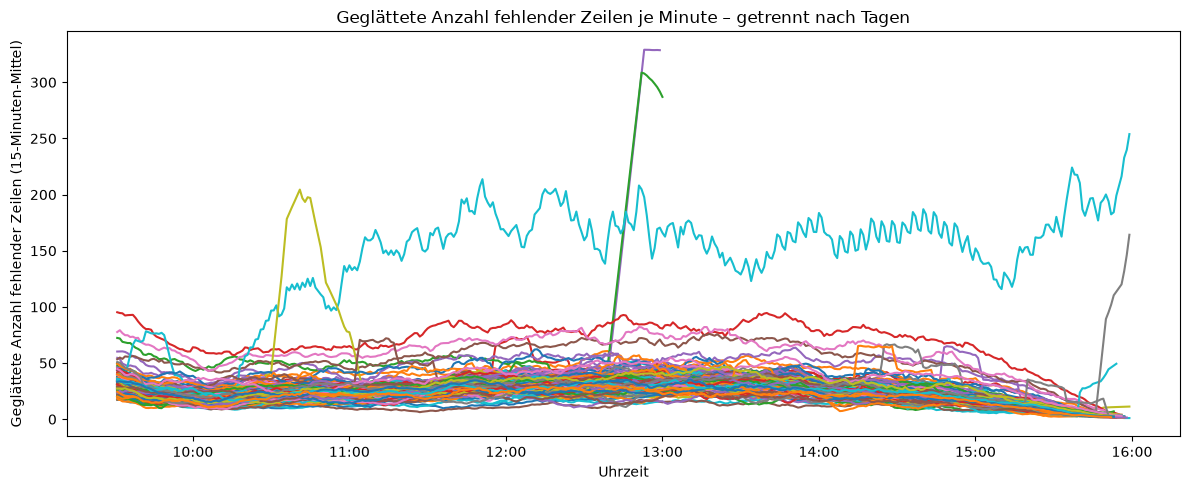

,rows_total,rows_missing,missing_%
datetime,,,
2026-02-13,189513,7567,3.992866
2026-03-11,189033,8868,4.691244
2026-04-01,189032,9196,4.864785
2026-01-02,189032,12176,6.441237
2026-01-30,189029,9110,4.819366


In [6]:
# Zelle 6: Missing Coverage pro Tag
coverage = pp.analyze_missing_coverage(
    df,
    smoothing_window=15,
    show_plot=True,
    print_table=False
)
coverage.sort_values("rows_total", ascending=False).head(5)

Es ist zu erkennen, dass es drei Tage gibt, die herausstechen:
 - **28.11.2025**: Black Friday
 - **24.12.2025**: Weihnachten
 - **06.01.2026**: Für uns nicht erklärbar

An Black Friday und Weihnachten schloss der Markt früher. Diese Informationen stammen vom [Marktkalender](https://www.nasdaqtrader.com/trader.aspx?id=calendar).

 Diese drei Tage werden aus dem Datensatz entfernt. Das ist nicht korrekt, weil dann der Datensatz nicht komplett ist, jedoch ist das eine einfache Lösung. Der Aufwand würde extrem steigen, wenn man diese Daten nicht extrahieren würde. Nach der Entfernung wird die Coverage nochmals überprüft:

/Users/ryanmikus/Development/Python/00_Quant/HS25_ML/pairs_trading/preprocessing/data_quality.py:142: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))


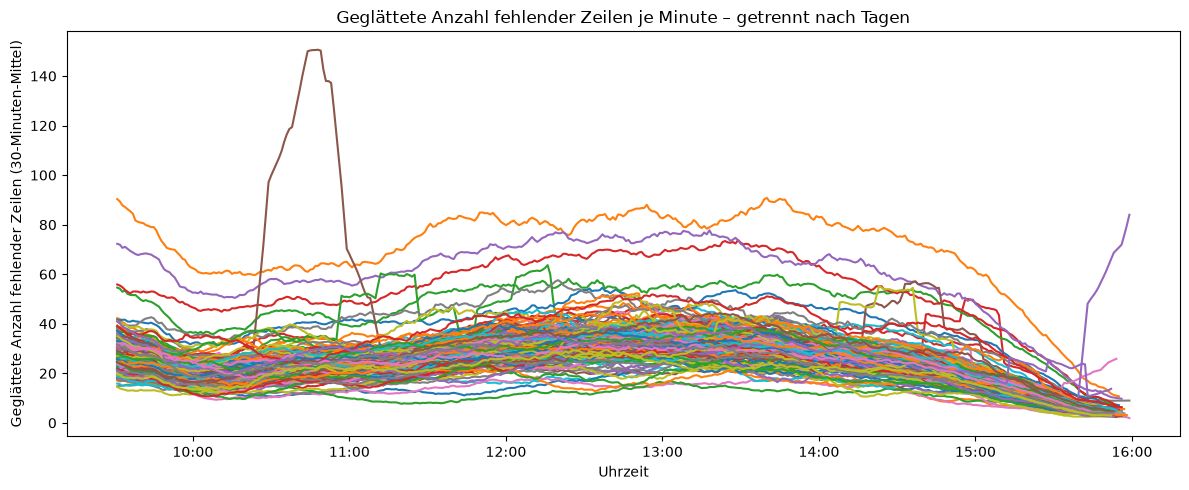

,rows_total,rows_missing,missing_%
datetime,,,
2025-12-26,188070,26798,14.248950
2025-12-31,187590,22674,12.086998
2025-12-30,187590,20500,10.928088
2025-12-29,188068,17738,9.431695
2025-12-23,188071,15182,8.072483


In [7]:
# Zelle 7: Coverage nach Early-Close-Filter erneut prüfen
# Early-close Tage manuell entfernen
early_close_days = [
    pd.to_datetime("2025-11-28").date(),
    pd.to_datetime("2025-12-24").date(),
    pd.to_datetime("2026-01-06").date(),
]

# Datum aus der datetime-Spalte ableiten und Maske bauen
dt = pd.to_datetime(df["datetime"], errors="coerce")
mask_keep = ~dt.dt.date.isin(early_close_days)

# Gefiltertes DataFrame
df_no_early_close = df.loc[mask_keep].copy()

# Coverage nach Entfernen der Early-close Days neu berechnen
coverage_no_early_close = pp.analyze_missing_coverage(
    df_no_early_close,
    smoothing_window=30,
    show_plot=True,
    print_table=False,
)
coverage_no_early_close.sort_values("rows_missing", ascending=False).head(5)

Um die hohen Spikes zu entfernen wird folgendes gemacht:

/var/folders/00/k8c8xvw575l2_kgdcbf1vq8m0000gn/T/ipykernel_40115/1602723673.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))


Tage mit geglätteter gleichzeitiger Missing-Anzahl > 100:


date
2026-01-20    150.6
Name: count_smooth, dtype: float64

/Users/ryanmikus/Development/Python/00_Quant/HS25_ML/pairs_trading/preprocessing/data_quality.py:142: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))


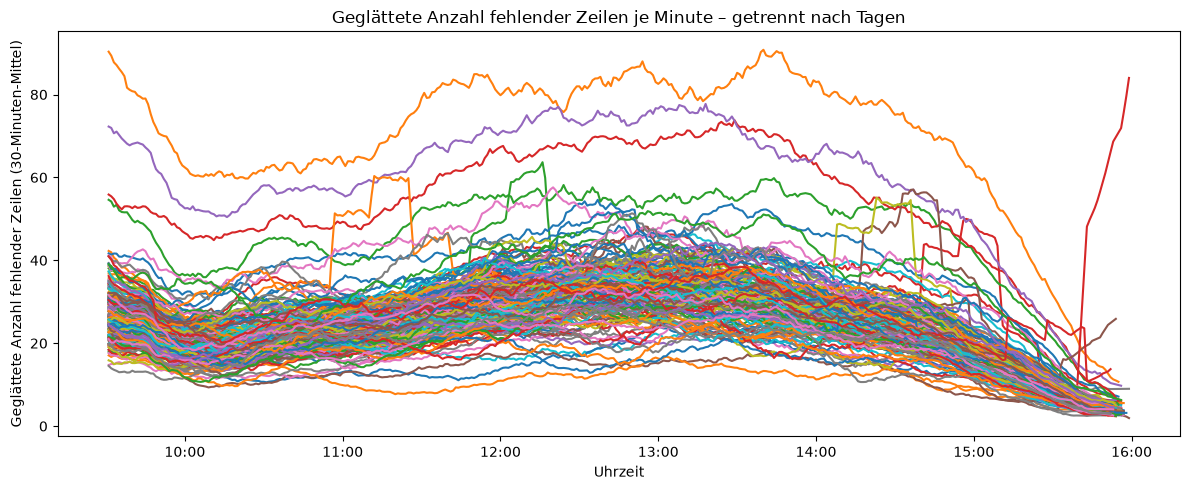

Aktualisierte early_close_days: [datetime.date(2025, 11, 28), datetime.date(2025, 12, 24), datetime.date(2026, 1, 6), datetime.date(2026, 1, 20)]


In [8]:
# Zelle 7b: Tag mit auffällig hoher gleichzeitiger Missing-Anzahl finden und entfernen
# Nutzt dieselbe Glättung wie der Plot oben, um zu prüfen, an welchem Tag die
# geglättete Anzahl gleichzeitig fehlender Aktien an irgendeinem Zeitpunkt über 100 steigt.
dtc = pd.to_datetime(df_no_early_close["datetime"], errors="coerce")
is_missing_row = df_no_early_close.isna().any(axis=1)

missing_time_by_day = (
    pd.DataFrame({"date": dtc.dt.date[is_missing_row], "time": dtc.dt.time[is_missing_row]})
    .groupby(["date", "time"])
    .size()
    .rename("count")
    .reset_index()
)
missing_time_by_day["time_dt"] = pd.to_datetime(missing_time_by_day["time"].astype(str))

smoothed_parts = []
for d, sub in missing_time_by_day.groupby("date"):
    sub = sub.sort_values("time_dt").copy()
    sub["count_smooth"] = sub["count"].rolling(window=30, min_periods=1, center=True).mean()
    smoothed_parts.append(sub)
missing_time_smoothed = pd.concat(smoothed_parts, ignore_index=True)

max_smooth_per_day = missing_time_smoothed.groupby("date")["count_smooth"].max().sort_values(ascending=False)
spike_days = max_smooth_per_day[max_smooth_per_day > 100]

print("Tage mit geglätteter gleichzeitiger Missing-Anzahl > 100:")
display(spike_days)

# Auffällige Tage aus dem Datensatz entfernen (wie bei den Early-Close-Tagen oben)
early_close_days += list(spike_days.index)

dt = pd.to_datetime(df["datetime"], errors="coerce")
mask_keep = ~dt.dt.date.isin(early_close_days)
df_no_early_close = df.loc[mask_keep].copy()

coverage_no_early_close = pp.analyze_missing_coverage(
    df_no_early_close,
    smoothing_window=30,
    show_plot=True,
    print_table=False,
)
print("Aktualisierte early_close_days:", early_close_days)

Es sticht ein Tag heraus, an dem die geglättete Anzahl gleichzeitig fehlender Aktien deutlich über der restlichen Verteilung liegt (Schwelle: 100, siehe Ausgabe oben). Das ist kein bekannter Markt-Sondertag, sondern deutet auf ein Problem bei der Datensammlung an diesem Tag hin. Solche Tage werden deshalb, wie die Early-Close-Tage, aus dem Datensatz entfernt.


Ein paar Tage haben mehr fehlende Tage, aber da sie dem Trend folgen, werden sie nicht ausgeschlossen. Es ist zu bemerken, dass die grössten Abweichungen um Weihnachten und Neujahr sind.

Es ist ein Trend zu erkennen in den fehlenden Daten. Die Daten wurden auf den `datetime` aggregiert, um den Trend genauer untersuchen zu können, jedoch liegt dies nicht im Rahmen dieses Projekts. Der Trend ist im folgenden Histogramm besser zu erkennen:

/Users/ryanmikus/Development/Python/00_Quant/HS25_ML/pairs_trading/preprocessing/data_quality.py:206: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  missing_time_df["time_dt"] = pd.to_datetime(missing_time_df["time_only"].astype(str))


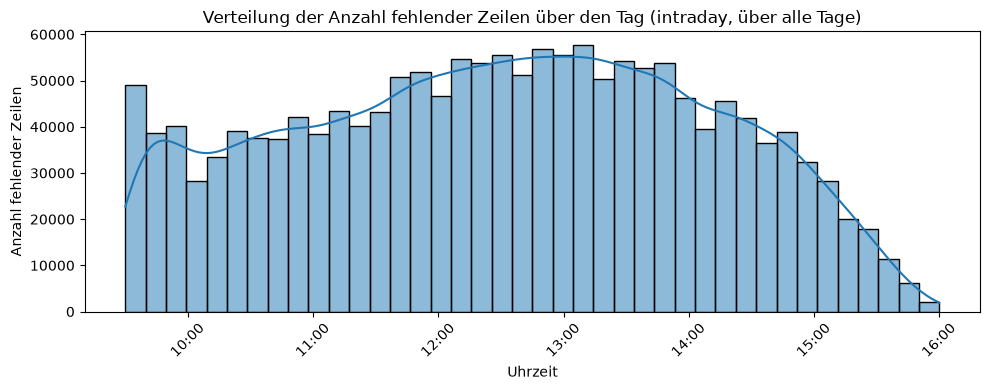

In [9]:
# Zelle 8: Aggregierte Visualisierung der Coverage
missing_time_df = pp.plot_intraday_missing_distribution(df_no_early_close, bins=40, kde=True)

Nun wird untersucht, ob und wie diese fehlenden Daten konsekutiv vorkommen. Diese Lücken sind ein Problem, falls sie zu gross werden. Es ist zu bemerken, dass die Zahlen hier nicht auf `datetime` aggregiert wurden, wie vorhin.

In der folgenden Analyse werden **Lücken (NaN-Werte)** in den Kursdaten aller Aktien untersucht. Die Funktion `analyze_nan_luecken_global()` sucht für jede Aktie zusammenhängende Bereiche mit fehlenden Werten und berechnet die Länge der Lücke in Minuten und die relative Preisänderung zwischen den Zeitpunkten davor und danach.

Gefundene Lücken insgesamt: 1171582


,gap_len,rel_change
count,1.171582e+06,1.171582e+06
mean,2.386176e+00,7.142302e-06
std,1.377864e+00,1.167079e-03
min,2.000000e+00,-5.001141e-02
25%,2.000000e+00,-4.546808e-04
50%,2.000000e+00,0.000000e+00
75%,2.000000e+00,4.669498e-04
max,1.075000e+03,9.315382e-02


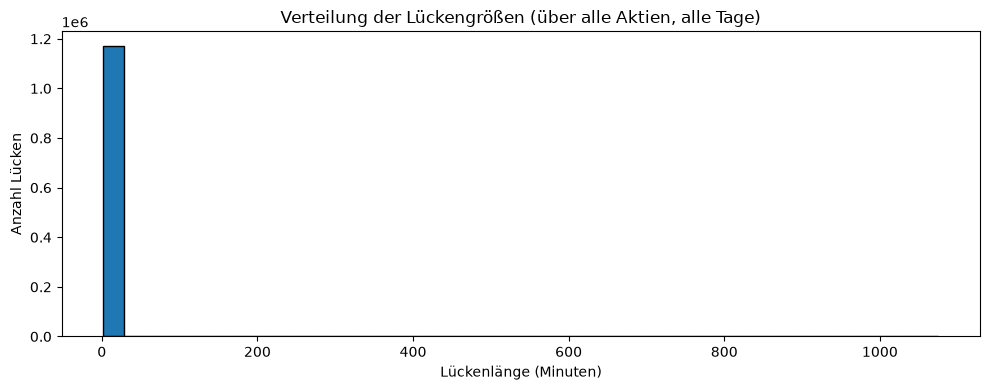

In [10]:
# Zelle 9: Überblick Zeitlücken (konsekutive NaNs)
nan_gaps_all = pp.analyze_nan_gaps_global(df_no_early_close)
print(f"Gefundene Lücken insgesamt: {len(nan_gaps_all)}")
display(nan_gaps_all.describe())
pp.plot_gap_length_hist(nan_gaps_all, bins=40, round_to_int=True)

Die statistische Auswertung zeigt, dass die meisten Lücken kurz sind und der Datensatz sollte deshalb kein Problem darstellen.

Das Histogramm visualisiert die Verteilung der Lückengrößen. Das Histogramm zeigt nicht besonders viel, aber den wesentlichen Punkt wird gut demonstriert: Der Großteil der Lücken ist sehr klein, längere Ausfälle sind sehr selten. Das deutet darauf hin, dass Datenunterbrechungen kurz und regelmäßig, aber nicht gravierend lang auftreten.

Probleme bereiten die grossen Lückengrössen aus, nicht die Kleinen. Nun werden folgende drei Tabellen ausgegeben:
 - Anzahl vorkommender Lücken pro Lückengrösse (in Minuten)
 - Anzahl Aktien mit mindestens einer Lücke > 5 Minuten
 - Anzahl Aktien mit mindestens einer Lücke > X Minuten (als Funktion von X)

In [11]:
# Zelle 10: Kernzahlen über Zeitlücken
gap_counts = pp.gap_len_counts(nan_gaps_all, min_gap=0, round_to_int=True)
print("Anzahl vorkommender Lücken pro Lückengröße (in Minuten):")
display(gap_counts.head(10))

long_gaps_tbl = pp.long_gap_summary(nan_gaps_all, threshold_min=5, round_to_int=True)
print(f"Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: {len(long_gaps_tbl)}")
display(long_gaps_tbl.head(10))

gap_stats = pp.gap_stats_stocks_with_min_gap(nan_gaps_all, round_to_int=True)
print("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:")
unique_mask = gap_stats['n_stocks'].map(gap_stats['n_stocks'].value_counts()).eq(1)
print(gap_stats[unique_mask])

Anzahl vorkommender Lücken pro Lückengröße (in Minuten):


,gap_len,count
0,2,898882
1,3,179442
2,4,53872
3,5,20612
4,6,8698
5,7,4264
6,8,2255
7,9,1298
8,10,743
9,11,493


Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: 196


,symbol,n_gaps,max_gap
0,LYV,4,1075
1,ERIE,2191,53
2,VMC,2,45
3,AIZ,1500,38
4,NDSN,1358,30
5,HSY,3,28
6,L,312,25
7,XYZ,1,23
8,GWW,494,22
9,CINF,731,21


Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:
    gap_length_min  n_stocks
3                4       430
4                5       399
5                6       196
6                7       157
7                8       123
8                9       108
9               10        89
10              11        69
11              12        58
12              13        53
13              14        41
14              15        35
15              16        28
16              17        24
17              18        18
18              19        16
19              20        11
20              21        10
21              22         9
22              23         8


Es ist interessant, dass jede Aktie mindestens eine kurze Lücke aufweist (siehe Tabelle oben). Um die letzte Tabelle zu visualisieren, wurde folgendes Diagramm erstellt:


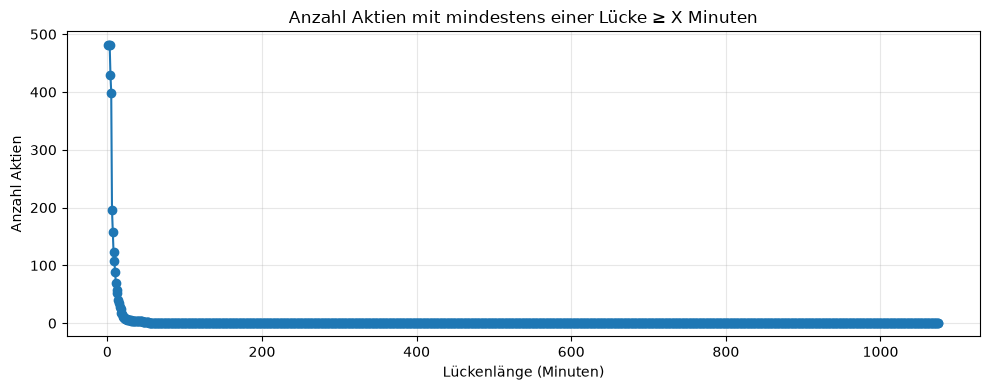

In [12]:
# Zelle 11: Aktien nach Zeitlückenlänge
pp.plot_stocks_vs_gap_threshold(gap_stats)

Dieses Diagramm sollte die Grundlage sein für die Entscheidung, welche Aktien aus dem Datensatz ausgeschlossen werden sollten. Da sie so "smooth" ist, wird es nach Bauchgefühl gemacht:

Es wurde entschieden, dass die Aktien mit Datenlücken, die **mindestens 16 Minuten** lang sind, entfernt werden.

In [13]:
# Zelle 12: Entfernung der Aktien mit zu grossen Zeitlücken
minute_threshold = 16

symbols_with_long_gaps = pp.find_symbols_with_long_gaps(
    nan_gaps_all,
    min_gap_len=minute_threshold,
)

print(f"Anzahl Aktien mit mindestens einer Lücke ≥ {minute_threshold} Minuten: {len(symbols_with_long_gaps)}")

df_clean = pp.drop_symbols(
    df_no_early_close,
    symbols_with_long_gaps,
    sort_by=["datetime"],
)

print(f"Verbleibende Aktien nach Filterung: {df_clean['symbol'].nunique()}")
print(f"Zeilen nach Filterung: {len(df_clean):,}")

Anzahl Aktien mit mindestens einer Lücke ≥ 16 Minuten: 28
Verbleibende Aktien nach Filterung: 453
Zeilen nach Filterung: 29,747,315


<h2 id="33">3.3. Duplikate & Preis-Ausreisser</h2>

Bevor im nächsten Abschnitt die Zeilenanzahl pro Aktie ausgewertet wird, müssen drei Arten von Fehlern behoben werden, die diese Analyse sonst verfälschen würden:

- **Duplikate**: mehrfach vorkommende `(datetime, symbol)`-Einträge.
- **Einzelne Preis-Ausreisser ("Bad Ticks")**: offensichtlich falsche Einzelwerte in den Rohdaten.
- **Preisniveau-Brüche (Aktiensplits)**: nicht bereinigte, dauerhafte Kursniveau-Sprünge.

Die Reihenfolge ist hier wichtig: Würde man zuerst die "erwartete Zeilenanzahl" pro Aktie bestimmen und danach erst Duplikate entfernen, könnte die Zeilenanzahl einzelner Aktien nachträglich unter das erwartete Niveau fallen, ohne dass die Filterung im nächsten Abschnitt das noch erkennt. Und würde man die Preisniveau-Brüche erst nach dem Auffüllen von Zeitlücken (Interpolation) korrigieren, könnte eine echte Datenlücke, die über einen solchen Bruch hinwegreicht, mit einem bedeutungslosen Zwischenwert interpoliert werden.

In [14]:
# Zelle 13: Duplikate entfernen
df_clean, dup_rows = pp.drop_duplicate_rows(
    df_clean,
    subset=["datetime", "symbol"],
    keep="first",
    return_duplicates=True,
    sort_by=["symbol", "datetime"],
)
print(f"Anzahl doppelter Einträge: {len(dup_rows)}")
print(f"Betroffene Aktien: {dup_rows['symbol'].nunique()}")
print("\nDuplikate pro Datum:")
print(dup_rows["datetime"].dt.date.value_counts().sort_index())

Anzahl doppelter Einträge: 12621
Betroffene Aktien: 453

Duplikate pro Datum:
datetime
2025-11-10     390
2026-01-02     906
2026-01-07     453
2026-01-14     453
2026-01-23     453
2026-01-27     453
2026-01-30     906
2026-02-06     906
2026-02-13    1359
2026-03-11     906
2026-03-13     453
2026-04-01     906
2026-04-10     906
2026-05-27     906
2026-06-05     906
2026-07-07     453
2026-07-17     906
Name: count, dtype: int64


Auffällig ist, dass fast jede Aktie mindestens ein Duplikat hat, wobei einzelne Aktien deutlich stärker betroffen sind als der Rest (siehe Ausgabe oben). Die Duplikate konzentrieren sich zudem auf einzelne Handelstage, an denen jeweils einige wenige Minuten für praktisch das gesamte Aktienuniversum doppelt vorkommen (siehe Verteilung der Duplikate pro Datum oben, jeweils ein Vielfaches der Anzahl Aktien). Das deutet auf einen erneuten bzw. teilweise wiederholten Abruf der Datensammlung an diesen Tagen hin, nicht auf zufällige Einzelfehler. Da `keep="first"` verwendet wird, bleibt pro `(datetime, symbol)` genau eine Zeile erhalten.


<h3 id="331">3.3.1. Preis-Ausreisser (Bad Ticks)</h3>

Um einzelne, offensichtlich falsche Kurswerte zu finden, wird die Ein-Minuten-Rendite von `close` je Aktie betrachtet. Bewegungen über 25% innerhalb einer Minute sind für einzelne Aktien praktisch ausgeschlossen und werden daher genauer untersucht.

In [15]:
# Zelle 14: Extreme Ein-Minuten-Bewegungen identifizieren
close_sorted = df_clean.sort_values(["symbol", "datetime"])
pct_change = close_sorted.groupby("symbol")["close"].pct_change()
extreme = pct_change.abs() > 0.25

print(f"Ein-Minuten-Bewegungen > 25%: {extreme.sum()}")
display(
    close_sorted.loc[extreme, ["symbol", "datetime", "close"]]
    .assign(pct=pct_change[extreme])
    .sort_values("pct", key=abs, ascending=False)
    .head(10)
)

Ein-Minuten-Bewegungen > 25%: 16


,symbol,datetime,close,pct
15744096,KLAC,2026-06-11 20:00:00+00:00,2411.639893,9.005725
1526170,AMCR,2026-01-15 14:31:00+00:00,45.310001,4.137189
6756321,CRWD,2026-07-01 20:00:00+00:00,772.739990,3.000569
3712987,BKNG,2026-04-06 13:30:00+00:00,170.339996,-0.959388
15744097,KLAC,2026-06-12 13:30:00+00:00,239.350006,-0.900752
19234814,NFLX,2025-11-17 14:30:00+00:00,111.110001,-0.900096
15743706,KLAC,2026-06-11 13:30:00+00:00,223.338989,-0.895493
19505597,NOW,2025-12-18 14:30:00+00:00,156.445007,-0.800042
6756322,CRWD,2026-07-02 13:30:00+00:00,193.039993,-0.750188
6755931,CRWD,2026-07-01 13:30:00+00:00,192.080246,-0.748303


Ein auffälliger Ausreisser in der Tabelle oben ist **KLAC**: Der Schlusskurs springt innerhalb einer Minute um exakt Faktor 10 und fällt in der nächsten vorhandenen Minute grösstenteils wieder auf das ursprüngliche Niveau zurück. Ein Blick in die Rohdaten bestätigt den Fehler direkt an der Quelle: Diese Bar hat zudem ein Volumen von 0, was auf einen fehlerhaften "Official Close"-Print der Datenquelle hindeutet und nicht auf einen echten Trade.

Ein einfacher Schwellenwert auf die Ein-Minuten-Rendite allein würde hier aber auch echte, grosse Kursbewegungen fälschlich erfassen (z. B. reale Übernacht-Gaps durch Earnings). Deshalb wird stattdessen nach einem **V-förmigen Snap-back** gesucht: ein extremer Sprung, der sich in der unmittelbar folgenden Minute grösstenteils wieder zurückbildet. Das ist die Signatur eines einzelnen Fehlwerts, nicht einer echten Kursbewegung.


In [16]:
# Zelle 15: Preis-Ausreisser (Bad Ticks) erkennen und maskieren
spike_mask = pp.flag_price_spikes(df_clean, price_col="close", threshold=0.5, snapback_frac=0.3)

print(f"Erkannte Preis-Ausreisser (V-förmiger Snap-back): {spike_mask.sum()}")
display(df_clean.loc[spike_mask, ["symbol", "datetime", "close"]])

df_clean.loc[spike_mask, "close"] = np.nan

Erkannte Preis-Ausreisser (V-förmiger Snap-back): 2


,symbol,datetime,close
6756321,CRWD,2026-07-01 20:00:00+00:00,772.739990
15744096,KLAC,2026-06-11 20:00:00+00:00,2411.639893


In einer ersten Version wurde hier nur der KLAC-Ausreisser gefunden. Ein zweiter, identisch aussehender Fall blieb zunächst unentdeckt: `CRWD` hatte denselben Fehler (Volumen 0, Sprung um denselben Faktor), aber `flag_price_spikes()` fand ihn zunächst nicht, weil dieser Zeitpunkt damals am Rand des verfügbaren Datensatzes lag und keine Folgeminute für den Snap-back-Vergleich existierte.

Deshalb wurde die Funktion um einen Randfall-Check ergänzt: Existiert keine Folgezeile, wird stattdessen geprüft, ob der Wert *sowohl* stark vom Vorgänger *als auch* vom Median des jeweiligen Tages abweicht. Damit werden nun beide Fälle korrekt erkannt, ohne neue False Positives (siehe Kontrolle unten). Beide Werte werden auf `NaN` gesetzt und im nächsten Schritt (Zeitlücken auffüllen) wie jede andere fehlende Minute zeitbasiert interpoliert bzw. am Rand fortgeschrieben, die bestehende Bereinigungslogik wird also wiederverwendet statt eine neue eingeführt.


<h3 id="332">3.3.2. Preisniveau-Brüche (Aktiensplits)</h3>

Bei der Untersuchung des KLAC-Ausreissers oben fällt auf: Selbst nach der Korrektur des einzelnen Bad Ticks kehrt der Kurs nicht auf sein ursprüngliches Niveau (~2300) zurück, sondern bleibt dauerhaft bei ~230. Das ist kein Bad Tick mehr, sondern ein permanenter Bruch im Preisniveau – typischerweise ein nicht bereinigter Aktiensplit. `flag_price_spikes()` erkennt solche Brüche bewusst **nicht** (kein Snap-back), deshalb wird dafür eine eigene Prüfung eingeführt: Der tägliche Median-Kurs je Aktie wird betrachtet, und Tage mit einem Verhältnis zum Vortag ausserhalb von [0.6, 1.6] werden markiert.

In [17]:
# Zelle 16: Preisniveau-Brüche (Aktiensplits) finden
splits = pp.detect_price_level_breaks(df_clean, price_col="close", lower=0.6, upper=1.6)
print(f"Erkannte Preisniveau-Brüche: {len(splits)}")
display(splits)

Erkannte Preisniveau-Brüche: 6


,symbol,date,ratio
0,AMCR,2026-01-15,4.994366
1,BKNG,2026-04-06,0.041465
2,CRWD,2026-07-01,0.254623
3,KLAC,2026-06-11,0.107621
4,NFLX,2025-11-17,0.098855
5,NOW,2025-12-18,0.193488


Die gefundenen Brüche (siehe Ausgabe und Tabelle oben) decken sich grösstenteils mit den Aktien, die bereits in der Ein-Minuten-Bewegungs-Tabelle oben auffielen. Eine Ausnahme kann eine Aktie mit einer grossen, aber realen Kursbewegung sein, die keinen dauerhaften Bruch darstellt und daher korrekt nicht als Split eingestuft wird. Keiner der gefundenen Brüche zeigt einen Snap-back (sonst wäre er bereits oben als Bad Tick erkannt worden), alle sind also dauerhaft: Ein Verhältnis unter 1 bedeutet einen Vorwärts-Split (Kurs sinkt), ein Verhältnis über 1 einen Reverse-Split (Kurs steigt). Da die Rohdaten offenbar nicht split-adjustiert sind, muss das hier nachgeholt werden.


In [18]:
# Zelle 17: Historische Preise für erkannte Brüche anpassen (Split-Adjustierung)
df_clean = pp.adjust_for_price_level_breaks(df_clean, splits, price_cols=("close",))

# Kontrolle: Tagesmedian von KLAC unmittelbar um den Split herum
klac_check = (
    df_clean[df_clean["symbol"] == "KLAC"]
    .assign(date=lambda d: d["datetime"].dt.date)
    .groupby("date")["close"].median()
)
window = (klac_check.index >= pd.to_datetime("2026-06-08").date()) & (klac_check.index <= pd.to_datetime("2026-06-15").date())
print(klac_check[window])

date
2026-06-08    227.536471
2026-06-09    227.258274
2026-06-10    232.228500
2026-06-11    232.228500
2026-06-12    250.380005
2026-06-15    254.404999
Name: close, dtype: float64


Die Zeitreihe ist jetzt durchgängig: Der Tagesmedian unmittelbar vor und nach dem erkannten Bruchdatum liegt auf demselben Niveau, statt eines abrupten Sprungs wie zuvor (siehe Ausgabe oben). Alle Preise **vor** dem jeweiligen Bruch-Datum wurden mit dem gefundenen Verhältnis multipliziert, sodass die gesamte Historie eines Symbols auf einer Skala liegt. Das betrifft nur `close` (die einzige für dieses Projekt verwendete Preis-Spalte); `open`, `high`, `low`, `volume` bleiben unverändert, wie in Abschnitt 3 einleitend festgehalten.


Die kleinen Datenlücken werden im folgenden Schritt bereinigt. Datenlücken werden gefüllt indem, sie interpoliert werden und in Edge-Cases wird von vorne/hinten aufgefüllt. Dazu wird die `close_filled` hinzugefügt, um die Daten nicht zu verfälschen. Anschliessend wird `close` entfernt.

In [19]:
# Zelle 18: Zeitlücken auffüllen
df_filled = pp.fill_close_gaps_per_symbol(
    df_clean,
    value_col="close",
    out_col="close_filled",
)

print("Fehlende Werte im Original (gefiltert):", df_clean["close"].isna().sum())
print("Fehlende Werte in close_filled:", df_filled["close_filled"].isna().sum())
df_filled = df_filled.drop(columns=["close"])

Fehlende Werte im Original (gefiltert): 1164065
Fehlende Werte in close_filled: 0


<h2 id="34">3.4. Fehlende Daten (Zeilen)</h2>

Da nun keine Datenlücken vorkommen, wird nun die Länge Daten pro Aktie analysiert.

In [20]:
# Zelle 19: Zeitreihenlängen
lengths = pp.symbol_lengths(df_filled)

print("Häufigste Längen:")
print(lengths.value_counts().sort_index())

Häufigste Längen:
65252      1
65253      1
65590      1
65594      1
65604      1
65610      1
65616      3
65618      1
65619      1
65622      1
65623      1
65627      2
65629      1
65630      2
65631      2
65633      2
65634      2
65635      5
65636      3
65637      6
65638      3
65639     10
65640     15
65641     21
65642     86
65643    280
Name: count, dtype: int64


Vereinzelte Aktien haben ausreissende Datenlängen. Diese sind problematisch. Zunächst wird untersucht, um welche Aktien es sich handelt.

In [21]:
# Zelle 20: Aktien mit falschen Zeitreihenlängen (exakter Abgleich)
expected_length = pp.expected_length_mode(lengths)
print(f"Erwartete Anzahl Zeilen pro Symbol: {expected_length}\n")

bad_symbols_exact = pp.symbols_with_unexpected_length(lengths, expected_length)
print(f"{len(bad_symbols_exact)} von {len(lengths)} Symbolen weichen exakt ab.\n")
print("Kürzeste Zeitreihen:")
print(bad_symbols_exact.sort_values().head(10))

Erwartete Anzahl Zeilen pro Symbol: 65643

173 von 453 Symbolen weichen exakt ab.

Kürzeste Zeitreihen:
symbol
WDAY    65252
AIG     65253
JBL     65590
AMP     65594
ROK     65604
KEYS    65610
ABT     65616
UPS     65616
MTB     65616
WRB     65618
dtype: int64


Bei exaktem Abgleich weicht ein grosser Teil aller Aktien ab (siehe Ausgabe oben). Das allein deutete zunächst auf einen Fehler hin: In einer früheren Version dieser Zelle wurde das Ergebnis von `symbols_with_unexpected_length()` (eine Series, indexiert nach Aktien-Namen, mit der jeweiligen Zeilenanzahl als Wert) direkt als `symbols_to_drop` an `drop_symbols()` übergeben. Dort wird intern `pd.Index(symbols_to_drop)` gebildet, das verwendet aber die **Werte** der Series (die Zeilenanzahlen) und nicht deren **Index** (die Aktien-Namen). Der Vergleich `df[symbol_col].isin(symbols_to_drop)` traf dadurch nie zu, und es wurde nie eine Aktie entfernt (sichtbar am Vorher/Nachher-Vergleich weiter unten: die Anzahl blieb unverändert). Der Fix ist, stattdessen `bad_symbols.index` zu übergeben.

Mit dem korrigierten Filter stellt sich aber eine zweite Frage: Ist ein *exakter* Abgleich überhaupt das richtige Kriterium? Ein Blick auf die Verteilung zeigt (siehe Ausgabe oben): Die meisten „abweichenden" Aktien fehlen nur um sehr wenige Zeilen, während die kürzesten Zeitreihen einen klaren Bruch zur übrigen Verteilung zeigen, deutlich weiter vom Maximum entfernt als der Rest. Ein exakter Abgleich ist damit der falsche Massstab, er würde grösstenteils normale, minimale Restlücken statt echter Ausreisser bestrafen. Stattdessen wird eine Toleranz von 0.5% der erwarteten Länge verwendet (ein fester, grosszügig gewählter Prozentsatz, kein aus dieser Verteilung abgeleiteter Wert), wodurch nur die echten Ausreisser entfernt werden.


In [22]:
# Zelle 21: Aktien mit falschen Zeitreihenlängen (mit Toleranz)
bad_symbols = pp.symbols_with_unexpected_length(lengths, expected_length, tolerance=0.005)

if bad_symbols.empty:
    print("Alle Symbole liegen innerhalb der Toleranz – keine Entfernung nötig.")
    symbols_to_drop = []
else:
    print(f"{len(bad_symbols)} Symbole ausserhalb der Toleranz gefunden:\n")
    print(bad_symbols)
    symbols_to_drop = bad_symbols.index

2 Symbole ausserhalb der Toleranz gefunden:

symbol
WDAY    65252
AIG     65253
dtype: int64


In [23]:
# Zelle 22: Entfernen der Aktien mit falschen Zeitreihenlängen
n_before = df_filled["symbol"].nunique()

df_filled = pp.drop_symbols(
    df_filled,
    symbols_to_drop,
)

n_after = df_filled["symbol"].nunique()
print(f"Verbleibende Aktien: {n_after} (vorher: {n_before})")

Verbleibende Aktien: 451 (vorher: 453)


<h2 id="35">3.5. Validierung & Speicherung</h2>

Die Daten wurden nun bereinigt. Eine kurze Überprüfung zeigt, dass noch genug Daten vorhanden sind. Somit sind sowohl Menge und Qualität gesichert.

In [24]:
# Zelle 23: Entfernte Symbole
symbols_after = set(df_filled["symbol"].unique())
removed_symbols = symbols_beginning - symbols_after

print("Anzahl Aktien zu Beginn:", len(symbols_beginning))
print("Anzahl Aktien nach Bereinigung:", len(symbols_after), "\n")
print("Entfernte Aktien:", len(removed_symbols))
print(sorted(removed_symbols))

Anzahl Aktien zu Beginn: 523
Anzahl Aktien nach Bereinigung: 451 

Entfernte Aktien: 72
['AIG', 'AIZ', 'ALGN', 'ARES', 'AVY', 'BIIB', 'BK', 'BNY', 'BR', 'CAG', 'CASY', 'CBOE', 'CIEN', 'CINF', 'COHR', 'CPB', 'CRH', 'CRL', 'CTRA', 'CVNA', 'DAY', 'DD', 'ECHO', 'EPAM', 'ERIE', 'ESS', 'FDXF', 'FI', 'FISV', 'FIX', 'FLEX', 'GL', 'GWW', 'HOLX', 'HONA', 'HSY', 'IEX', 'IPG', 'J', 'JBHT', 'JKHY', 'K', 'L', 'LITE', 'LKQ', 'LW', 'LYV', 'MHK', 'MMC', 'MOH', 'MPWR', 'MRSH', 'MRVL', 'MTCH', 'NDSN', 'NVR', 'PAYC', 'POOL', 'SATS', 'SNA', 'SNDK', 'SOLS', 'STE', 'TPL', 'TT', 'UHS', 'VEEV', 'VMC', 'VRT', 'WAB', 'WDAY', 'XYZ']


In [25]:
# Zelle 24: Validierung der Datensäuberung
df_final = pp.validate_and_finalize_df(df_filled)

DataFrame validation passed
  - rows: 29604189
  - symbols: 451
  - start: 2025-11-07 14:30:00+00:00
  - end: 2026-07-17 20:00:00+00:00
  - filled_rows: None


Der Datensatz ist validiert und finalisiert. Die Anzahl verbleibenden Aktien ist genügend.

Zum Schluss werden die gesäuberten Daten noch gespeichert. Im Verlauf des Projektes wurde von CSV-Format zum Parquet-Format gewechselt, weil das Einlesen sehr lange dauerte. Dieses braucht auch weniger Speicherplatz.

In [26]:
# Zelle 25: Speicherung der gesäuberten Daten
io.save_preprocessed_data(
    df_final,
    data_dir="data",
    basename="market_data_cleaned",
)


[Preprocessed Data (to be saved)]
Shape: (29604189, 7)
Spalten: ['symbol', 'datetime', 'open', 'high', 'low', 'volume', 'close_filled']

Head:
  symbol                  datetime        open        high         low  \
0      A 2025-11-07 14:30:00+00:00  146.520004  147.119995  145.729996   
1      A 2025-11-07 14:31:00+00:00         NaN         NaN         NaN   
2      A 2025-11-07 14:32:00+00:00  146.089996  146.089996  146.089996   
3      A 2025-11-07 14:33:00+00:00         NaN         NaN         NaN   
4      A 2025-11-07 14:34:00+00:00  146.049698  146.049698  146.049698   

    volume  close_filled  
0  13361.0    145.729996  
1      NaN    145.909996  
2    427.0    146.089996  
3      NaN    146.069847  
4   1387.0    146.049698  

Gespeichert als data/market_data_cleaned.parquet


Die Daten sind streng genommen nicht sauber. Die Spalte `close_filled` ist sauber, aber die anderen Spalten werden nicht gross betrachtet in der EDA und für die Features werden sie gar nicht beachtet.

Die Daten sind auch nicht im Format *tidy data*. Diese Entscheidung wurde getroffen, weil es Zeitreihen sind. Stattdessen sind sie nach `Symbol` und innerhalb von `Symbol` nach `datetime` sortiert. Dies wurde akzeptiert, weil es Zeitreihen sind.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="02_Datensammlung.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="04_Explorative_Datenanalyse.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>